# T06 — Single-particle backward trajectory, manual check

Scope (per `tasks.md` T06 and the 2026-09-22 task instructions):

- `iste.trajectory.run_backward_trajectory` — repeatedly calls T05's
  `backward_euler_maruyama_step` (no new physics/equations here);
- a fixed backward-time checkpoint schedule `t0, t0-dt, t0-2dt, ...` computed directly
  from `n_steps`/`dt`, independent of the particle's validity;
- once the particle becomes invalid, propagation stops (no further T05 calls) but the
  trajectory array is never truncated -- the last valid state is carried forward,
  explicitly marked invalid, into every remaining recorded state.

One particle only -- no forcing ensemble, no multi-particle arrays, no 7-day production
run. `n_steps`/`dt_seconds` are ordinary experiment parameters, not hard-coded constants.

In [1]:
import os
import sys

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import matplotlib.pyplot as plt

from iste.environment import GriddedFieldSource
from iste.geometry import metres_per_degree_longitude
from iste.trajectory import run_backward_trajectory

LAT = np.array([10.0, 20.0, 30.0])
LON = np.array([100.0, 110.0, 120.0])
T0 = np.datetime64("2020-01-01T06:00", "ns")
TIME = T0 - np.arange(9)[::-1] * np.timedelta64(3600, "s")  # t0-8h .. t0, hourly
DT = 900.0  # 15 minutes, seconds
ZERO_UV = np.zeros((3, 3))
ZERO_K = np.zeros((3, 3))


def make_ocean(uo_grid, vo_grid):
    n_t = len(TIME)
    uo = np.stack([uo_grid] * n_t)
    vo = np.stack([vo_grid] * n_t)
    return GriddedFieldSource(
        source_path="<synthetic>", time_name="time", time=TIME, lat_name="lat", lat=LAT,
        lon_name="lon", lon=LON, data={"uo": uo, "vo": vo}, fill_threshold=1e19,
    )

## 1. Small multi-step backward trajectory on a controlled field

Constant eastward ocean current (0.5 m/s), mild diffusivity (K=8 m^2/s), 8 steps of 15
minutes each (a 2-hour backward window).

In [2]:
ocean_ctrl = make_ocean(np.full((3, 3), 0.5), np.full((3, 3), -0.1))
k_ctrl = np.full((3, 3), 8.0)
n_steps = 8
traj = run_backward_trajectory(
    20.0, 110.0, T0, n_steps=n_steps, dt_seconds=DT, ocean_source=ocean_ctrl,
    k_lat=LAT, k_lon=LON, k_field=k_ctrl, rng=np.random.default_rng(42),
)
print(f"n_states={traj.n_states} (expected {n_steps + 1})")
print(f"elapsed backward time: {T0 - traj.timestamps[-1]} (expected {n_steps} * {DT}s)")
print(f"all valid: {bool(np.all(traj.valid))}")

n_states=9 (expected 9)
elapsed backward time: 7200000000000 nanoseconds (expected 8 * 900.0s)
all valid: True


### Checkpoint table

In [3]:
print(f"{'step':>4} {'timestamp':>22} {'lat':>10} {'lon':>10} {'log_w':>10} {'valid':>6}")
for i in range(traj.n_states):
    print(f"{i:>4} {str(traj.timestamps[i]):>22} {traj.lat[i]:>10.5f} {traj.lon[i]:>10.5f} "
          f"{traj.log_weight[i]:>10.6f} {str(bool(traj.valid[i])):>6}")

step              timestamp        lat        lon      log_w  valid
   0 2020-01-01T06:00:00.000000000   20.00000  110.00000   0.000000   True
   1 2020-01-01T05:45:00.000000000   19.99969  109.99604   0.000000   True
   2 2020-01-01T05:30:00.000000000   20.00151  109.99260  -0.000000   True
   3 2020-01-01T05:15:00.000000000   20.00092  109.98605  -0.000000   True
   4 2020-01-01T05:00:00.000000000   20.00138  109.98189  -0.000000   True
   5 2020-01-01T04:45:00.000000000   20.00127  109.97757  -0.000000   True
   6 2020-01-01T04:30:00.000000000   20.00292  109.97427  -0.000000   True
   7 2020-01-01T04:15:00.000000000   20.00495  109.97004  -0.000000   True
   8 2020-01-01T04:00:00.000000000   20.00483  109.96627  -0.000000   True


### Trajectory plot and weight-over-time plot

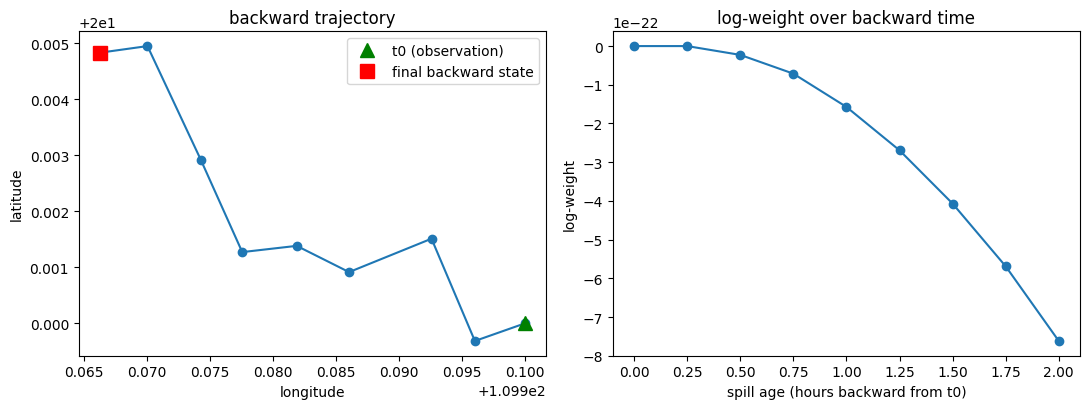

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].plot(traj.lon, traj.lat, "o-")
axes[0].plot(traj.lon[0], traj.lat[0], "g^", markersize=10, label="t0 (observation)")
axes[0].plot(traj.lon[-1], traj.lat[-1], "rs", markersize=10, label="final backward state")
axes[0].set_xlabel("longitude"); axes[0].set_ylabel("latitude")
axes[0].set_title("backward trajectory")
axes[0].legend()

age_hours = (T0 - traj.timestamps) / np.timedelta64(1, "h")
axes[1].plot(age_hours, traj.log_weight, "o-")
axes[1].set_xlabel("spill age (hours backward from t0)")
axes[1].set_ylabel("log-weight")
axes[1].set_title("log-weight over backward time")
fig.tight_layout()
plt.show()

## 2. One run where the particle becomes invalid

A strong eastward ocean current pushes the backward-stepping particle hard west, straight
into a masked "land" cell placed at the western edge of the domain.

In [5]:
uo_land = np.full((3, 3), 50.0)
uo_land[0, 0] = np.nan  # land at (lat=10, lon=100)
ocean_land = make_ocean(uo_land, np.zeros((3, 3)))

traj_land = run_backward_trajectory(
    10.0, 115.0, T0, n_steps=6, dt_seconds=DT, ocean_source=ocean_land,
    k_lat=LAT, k_lon=LON, k_field=ZERO_K, rng=np.random.default_rng(2),
)
print(f"n_states={traj_land.n_states} (never truncated, even though the particle stops early)")
print(f"first_invalid_index={traj_land.first_invalid_index}")
print(f"valid: {traj_land.valid}")
print(f"lat:   {traj_land.lat}")
print(f"lon:   {traj_land.lon}")

n_states=7 (never truncated, even though the particle stops early)
first_invalid_index=1
valid: [ True False False False False False False]
lat:   [10. 10. 10. 10. 10. 10. 10.]
lon:   [115. 115. 115. 115. 115. 115. 115.]


### Confirmation that propagation stops after invalidation

Every recorded state from `first_invalid_index` onward must be identical (frozen) to the
state at `first_invalid_index` -- no further movement, but every state is still present.

In [6]:
idx = traj_land.first_invalid_index
assert idx is not None, "expected this controlled case to hit land"
frozen_ok = (
    np.all(traj_land.lat[idx:] == traj_land.lat[idx])
    and np.all(traj_land.lon[idx:] == traj_land.lon[idx])
    and np.all(~traj_land.valid[idx:])
    and np.all(traj_land.valid[:idx])
)
print(f"state frozen and marked invalid from index {idx} onward, all {traj_land.n_states} states retained: {frozen_ok}")
assert frozen_ok

state frozen and marked invalid from index 1 onward, all 7 states retained: True


## Summary / known limitations

- `run_backward_trajectory` adds no new physics -- every displacement/weight update is
  produced entirely by T05's `backward_euler_maruyama_step`, called once per step.
- The checkpoint timestamp schedule (`t0, t0-dt, t0-2dt, ...`) is fixed and independent of
  validity, and always has exactly `n_steps + 1` entries -- confirmed above both for a
  fully-valid run and a run that becomes invalid partway through.
- Once invalid, no further T05 step calls are made, but the trajectory is never
  truncated: the last valid position/weight is carried forward, explicitly marked
  invalid, into every remaining recorded state.
- `n_steps` and `dt_seconds` are ordinary parameters here (`8` and `900.0` above) -- no 7
  day / 15 minute / any other window is hard-coded into this module.
- Exactly one particle; no forcing ensemble, no multi-particle arrays, no production-size
  run. `observation_pixel_id` tagging (T07), a forcing ensemble (T08), multi-particle/
  multi-member runs (T09), a diagnostics module (T10), storage (T11), a validation suite
  (T12), the sign-off artifact (T13), and KDE/likelihood/SMC/MCMC/AIS all remain
  unimplemented.